# Ray Train: TorchTrainer over a dataset

A TorchTrainer runs a training loop on one CPU worker and reads its shard of a Ray Dataset.

**When to use it.** Moving a PyTorch loop to Ray Train: the same code later scales to many workers and GPUs by changing ScalingConfig.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

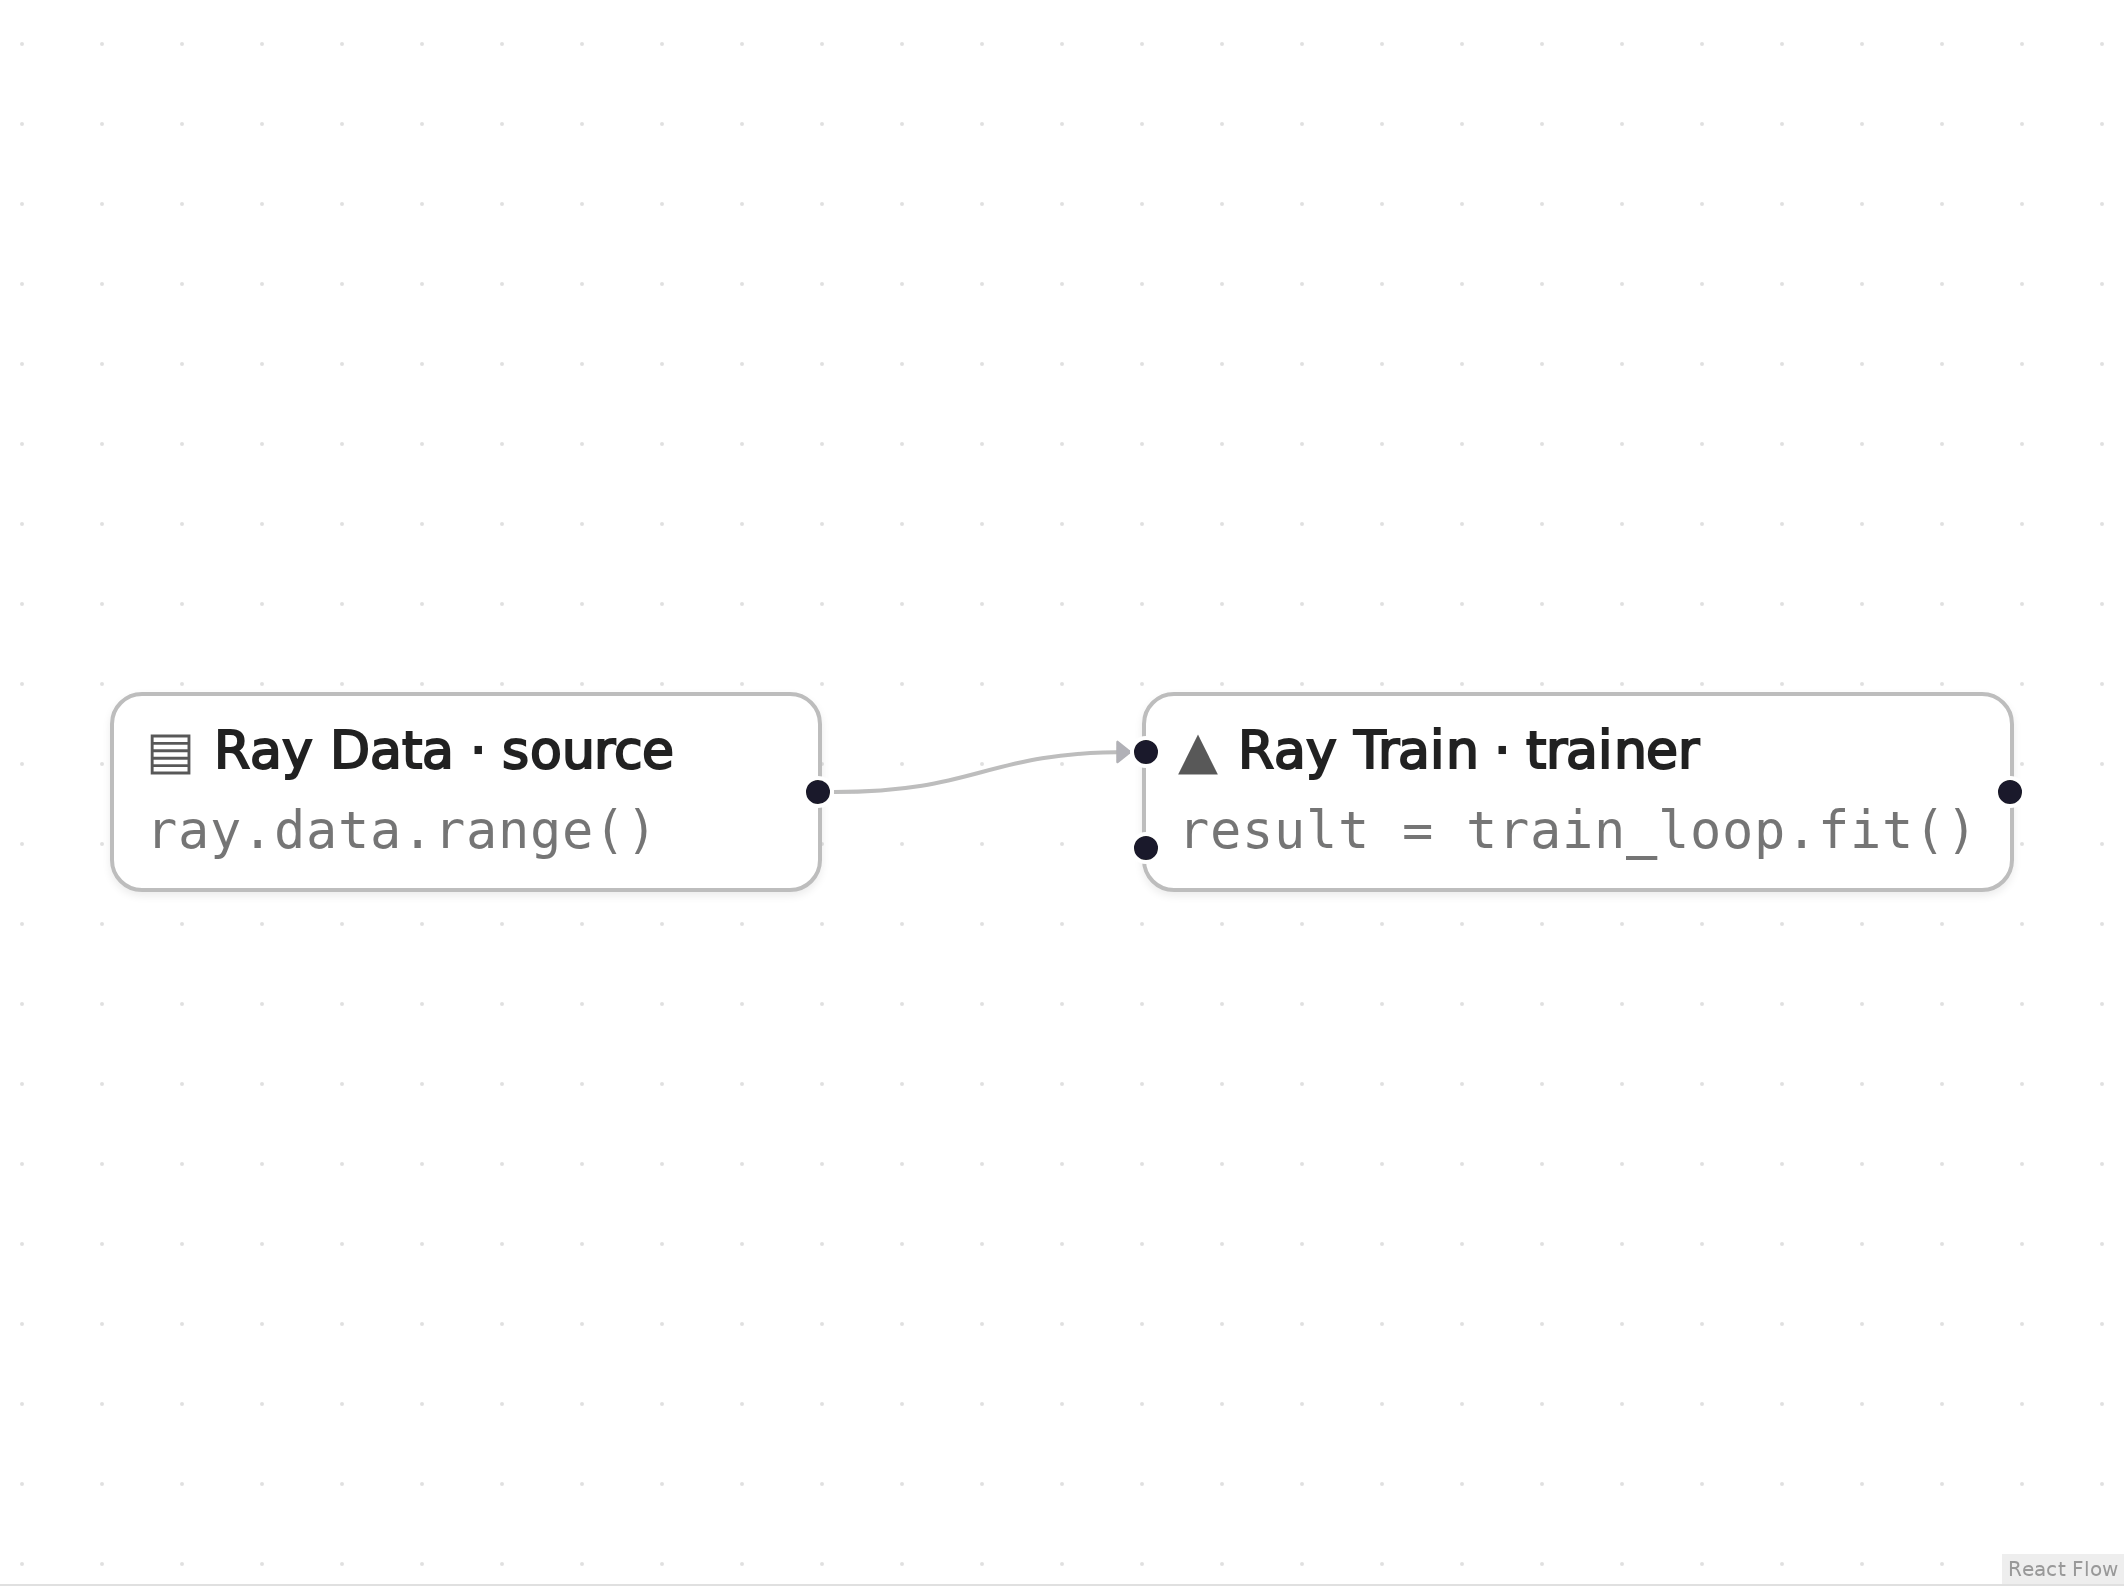

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
import os
import tempfile

import ray
import ray.train.torch
import torch


def train_loop():
    # Runs on every training worker. Fits y = 2x on the dataset's id column.
    shard = ray.train.get_dataset_shard("train")
    model = ray.train.torch.prepare_model(torch.nn.Linear(1, 1))
    optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
    for _ in range(20):
        for batch in shard.iter_torch_batches(batch_size=4, dtypes=torch.float32):
            x = batch["id"].unsqueeze(1)
            loss = torch.nn.functional.mse_loss(model(x), 2 * x)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    # Report the final loss together with a checkpoint, so the Result carries both.
    with tempfile.TemporaryDirectory() as tmp:
        torch.save(model.state_dict(), os.path.join(tmp, "model.pt"))
        ray.train.report({"loss": loss.item()}, checkpoint=ray.train.Checkpoint.from_directory(tmp))

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

import ray
from ray.train import ScalingConfig
from ray.train.torch import TorchTrainer

if not ray.is_initialized():
    ray.init()

ds = ray.data.range(8)

_trainer_n2 = TorchTrainer(train_loop, scaling_config=ScalingConfig(num_workers=1, use_gpu=False), datasets={"train": ds})
result = _trainer_n2.fit()

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
import os

assert result.error is None, result.error
assert result.checkpoint is not None
assert result.metrics["loss"] < 1.0, result.metrics
print("final loss:", round(result.metrics["loss"], 4))
print("checkpoint saved:", os.path.basename(result.checkpoint.path))

final loss: 0.0075
checkpoint saved: checkpoint_2026-11-07_20-30-28.904598


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3–5 and 7–8)

```python
# Generated with Eugo's visual Ray builder
...
import ray
from ray.train import ScalingConfig
from ray.train.torch import TorchTrainer
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Source** (node `n1`, line 10)

```python
ds = ray.data.range(8)
```

An eight-row dataset; the trainer gives each worker its shard as "train".

**Trainer** (node `n2`, lines 12–13)

```python
_trainer_n2 = TorchTrainer(train_loop, scaling_config=ScalingConfig(num_workers=1, use_gpu=False), datasets={"train": ds})
result = _trainer_n2.fit()
```

TorchTrainer(train_loop, scaling_config=ScalingConfig(num_workers=1, use_gpu=False), datasets={"train": ds}) launches the worker group; fit() blocks and returns a Result.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [5]:
ray.shutdown()